In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report



In [5]:
df = pd.read_csv("loan_approval_dataset.csv.xls")
df.columns = df.columns.str.strip()

In [6]:
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (4269, 13)

First 5 Rows:
   loan_id  no_of_dependents      education self_employed  income_annum  \
0        1                 2       Graduate            No       9600000   
1        2                 0   Not Graduate           Yes       4100000   
2        3                 3       Graduate            No       9100000   
3        4                 3       Graduate            No       8200000   
4        5                 5   Not Graduate           Yes       9800000   

   loan_amount  loan_term  cibil_score  residential_assets_value  \
0     29900000         12          778                   2400000   
1     12200000          8          417                   2700000   
2     29700000         20          506                   7100000   
3     30700000          8          467                  18200000   
4     24200000         20          382                  12400000   

   commercial_assets_value  luxury_assets_value  bank_asset_value loan_status  
0                 1


Loan Approval Distribution:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


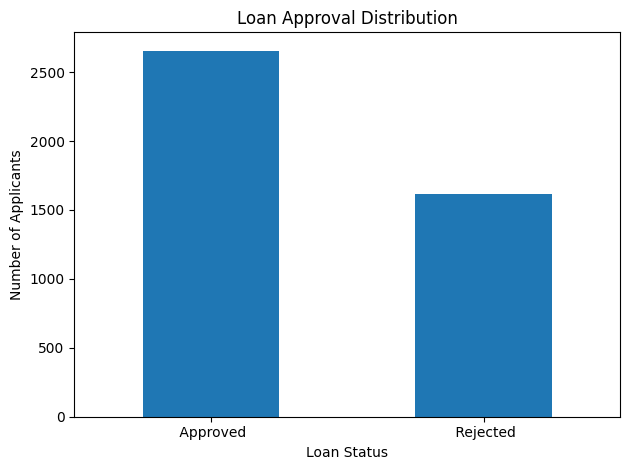

In [8]:
print("\nLoan Approval Distribution:")
print(df["loan_status"].value_counts())
df["loan_status"].value_counts().plot(
    kind="bar",
    title="Loan Approval Distribution",
    xlabel="Loan Status",
    ylabel="Number of Applicants"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [9]:
df = df.drop(columns=["loan_id"])

In [10]:
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median())

In [11]:
encoder = LabelEncoder()
for col in df.select_dtypes(include="object").columns:
    df[col] = encoder.fit_transform(df[col])


In [ ]:
X = df.drop(columns=["loan_status"])
y = df["loan_status"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

In [12]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Approved", "Rejected"]
))



Model Accuracy: 92.27 %

Classification Report:
              precision    recall  f1-score   support

    Approved       0.93      0.95      0.94       531
    Rejected       0.92      0.88      0.90       323

    accuracy                           0.92       854
   macro avg       0.92      0.91      0.92       854
weighted avg       0.92      0.92      0.92       854

